# Dataset cell-type annotation granularity

Analysis of results at three different annotation resolutions

In [1]:
import os
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc
import math
from bs4 import BeautifulSoup
import json
from pathlib import Path
import re
import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')
bold_prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')

import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

from analysis_helpers import *
import scib
from scib.metrics import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
ordered_metrics = [
    'CCENT', 'HOMO', 'JACC', 'PURITY', 'NMIF', 'ARIF', 'BKNN', 'FKNN', 'MCC', 'F1', 'NNMAP', 'CNENT', 'OCS', 'KSIM', 'CLISI',  # Cluster-as-prediction and knn
    'BLOGREG', 'FLOGREG',
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'GC', 'CASW', 'CDBI', 'CCH',
    'COMP', 'PPTPC', 'PSTDB', # Joint bio&batch
    'SCGRAPH', 'SCGRAPHM', 'SCGRAPHP', 'MORANI',
    'BASW', 'EMBDIV', 'CPCR', 'CPROBE', 'CPROBELR', 'CPROBERF', 'BRAS', 'CILISI', 'KBET'
]

bio = [
    'CCENT', 'HOMO', 'JACC', 'PURITY', 'NMIF', 'ARIF', 'BKNN', 'FKNN', 'MCC', 'F1', 'NNMAP', 'CNENT', 'OCS', 'KSIM', 'CLISI',  # Cluster-as-prediction and knn
    'BLOGREG', 'FLOGREG',
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'GC', 'CASW', 'CDBI', 'CCH',
    'COMP', 'PPTPC', 'PSTDB', # Joint bio&batch
    'SCGRAPH', 'SCGRAPHM', 'SCGRAPHP', 'MORANI'
]

batch = ['BASW', 'EMBDIV', 'CPCR', 'CPROBE', 'CPROBELR', 'CPROBERF', 'BRAS', 'CILISI', 'KBET']

In [3]:
def make_fig(df, y, ylabel, invert=False, show_legend=False, legend_ncols=3):
    fig, ax = plt.subplots(1, 1, figsize=(.8, 1.7))

    sns.lineplot(
        data=df, 
        x='LabelKey', 
        y=y, 
        hue='Integration', 
        marker='o', 
        markeredgewidth=0,
        markersize=2,
        linewidth=.5, 
        palette=INTEGRATION_COLOR_DICT, 
        ax=ax
    )

    if show_legend:
        sns.move_legend(
            ax, 
            "upper left", 
            bbox_to_anchor=(1, 1),
            ncols=legend_ncols,
            frameon=False,
            title="Integration",
            fontsize=5,
            title_fontsize=5,
            handlelength=1.0,
            columnspacing=0.8,
        )
    else:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    ax.patch.set_alpha(1.0)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=5)
    if invert:
        ax.invert_yaxis()
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
    for artist in ax.get_children():
        if hasattr(artist, 'get_rasterized') and artist.get_rasterized():
            print(artist, "is rasterized")
    fig.patch.set_alpha(0.0)
    ax.patch.set_alpha(0.0)
    return fig, ax

## Analyzing each dataset

### NeurIPS BMMC

Data file: `../results/source_data/neurips_bmmc_granularity.csv`

In [4]:
recalcs = pd.concat([
    pd.read_csv('../results/granularity_ablation/neurips_bmmc_final_metrics_gpu_l1/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/neurips_bmmc_final_metrics_gpu_l2/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/neurips_bmmc_final_metrics_gpu_l3/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/neurips_bmmc_final_metrics_cpu_l1/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/neurips_bmmc_final_metrics_cpu_l2/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/neurips_bmmc_final_metrics_cpu_l3/metrics/all-metrics.csv'),
])
recalcs = recalcs[recalcs['Integration'].isin(['cyclone-1', 'scanvi-1', 'equidistant-1', 'scdml-1', 'islander-1'])]
origs = pd.read_csv('../results/granularity_ablation/neurips_bmmc_v3/metrics/all-metrics.csv')

df1 = pd.concat([recalcs, origs])
df1 = df1.drop_duplicates(['Dataset', "Integration", 'Metric', 'LabelKey'], keep='first')

In [5]:
df1 = df1.pivot(index=['Dataset', 'Integration', 'LabelKey'], columns='Metric', values='Value').reset_index()

In [6]:
df1['BIO'] = (df1['BAMI'] + df1['CASW'] + df1['ISOLISI'] + df1['SCGRAPHM'] + df1['TRAJ']) / 5
df1['BATCH'] = (df1['CPCR'] + df1['BRAS'] + df1['KBET']) / 3
df1['OVERALL'] = df1['BIO'] * .6 + df1['BATCH'] * .4

In [7]:
df1['Integration'] = df1['Integration'].str[:-2]

In [8]:
df1['Integration'] = df1["Integration"].replace(NAME_MAP)

In [10]:
df1.to_csv('../results/spreadsheets/neurips_bmmc_granularity.csv', index=False)

In [9]:
for k in ['BAMI', 'CASW', 'SCGRAPHM', 'TRAJ', 'ISOLISI', 'KBET', 'CPCR', 'BRAS']:
    print(k)
    print('&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'broad_cell_type'][k], df1[df1['LabelKey'] == 'coarse_cell_type'][k]).statistic, 3), '&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'broad_cell_type'][k], df1[df1['LabelKey'] == 'cell_type'][k]).statistic, 3), '&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'coarse_cell_type'][k], df1[df1['LabelKey'] == 'cell_type'][k]).statistic, 3)
    )

BAMI
& 0.892 & 0.871 & 0.937
CASW
& 0.91 & 0.889 & 0.931
SCGRAPHM
& 0.817 & 0.715 & 0.838
TRAJ
& 0.991 & 0.868 & 0.865
ISOLISI
& 0.138 & 0.189 & 0.649
KBET
& 0.955 & 0.892 & 0.931
CPCR
& 0.886 & 0.871 & 0.985
BRAS
& 0.946 & 0.913 & 0.943


/tmp/ipykernel_3354098/1298101587.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['Rank'] = df1.groupby(['LabelKey'])['OVERALL'].rank(ascending=False, method='min')
/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


SignificanceResult(statistic=np.float64(0.9219219219219219), pvalue=np.float64(9.71292092627452e-16)) SignificanceResult(statistic=np.float64(0.903903903903904), pvalue=np.float64(3.4489238579727526e-15)) SignificanceResult(statistic=np.float64(0.957957957957958), pvalue=np.float64(7.162105167501895e-17))


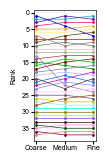

In [10]:
label_order = ['broad_cell_type', 'coarse_cell_type', 'cell_type']
df1['LabelKey'] = pd.Categorical(df1['LabelKey'], categories=label_order, ordered=True)
df1['Rank'] = df1.groupby(['LabelKey'])['OVERALL'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'broad_cell_type']['Rank'], df1[df1['LabelKey'] == 'coarse_cell_type']['Rank']),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'broad_cell_type']['Rank'], df1[df1['LabelKey'] == 'cell_type']['Rank']),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'coarse_cell_type']['Rank'], df1[df1['LabelKey'] == 'cell_type']['Rank'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'Rank', 'Rank', invert=True, show_legend=False)
#     plt.savefig('../publication_figures/neurips_bmmc_granularity_rank.svg', bbox_inches='tight')
    plt.show()

WilcoxonResult(statistic=np.float64(92.0), pvalue=np.float64(3.125937655568123e-05)) WilcoxonResult(statistic=np.float64(18.0), pvalue=np.float64(3.6816345527768135e-09)) WilcoxonResult(statistic=np.float64(37.0), pvalue=np.float64(8.3498889580369e-08))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


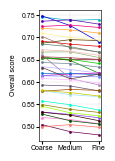

In [11]:
label_order = ['broad_cell_type', 'coarse_cell_type', 'cell_type']

print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['OVERALL'], df1[df1['LabelKey'] == 'coarse_cell_type']['OVERALL']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['OVERALL'], df1[df1['LabelKey'] == 'cell_type']['OVERALL']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'coarse_cell_type']['OVERALL'], df1[df1['LabelKey'] == 'cell_type']['OVERALL'])
)
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'OVERALL', 'Overall score', invert=False, show_legend=False)

#     plt.savefig('../publication_figures/neurips_bmmc_granularity_overall.svg', bbox_inches='tight')
    plt.show()

WilcoxonResult(statistic=np.float64(25.0), pvalue=np.float64(1.3154931366443634e-08)) WilcoxonResult(statistic=np.float64(10.0), pvalue=np.float64(6.257323548197746e-10)) WilcoxonResult(statistic=np.float64(23.0), pvalue=np.float64(9.313225746154785e-09))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


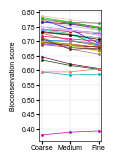

In [12]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['BIO'], df1[df1['LabelKey'] == 'coarse_cell_type']['BIO']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['BIO'], df1[df1['LabelKey'] == 'cell_type']['BIO']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'coarse_cell_type']['BIO'], df1[df1['LabelKey'] == 'cell_type']['BIO'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'BIO', 'Bioconservation score', invert=False, show_legend=False)

#     plt.savefig('../publication_figures/neurips_bmmc_granularity_bio.svg', bbox_inches='tight')
    plt.show()

WilcoxonResult(statistic=np.float64(175.0), pvalue=np.float64(0.006860146357212216)) WilcoxonResult(statistic=np.float64(218.0), pvalue=np.float64(0.04387893014063593)) WilcoxonResult(statistic=np.float64(292.0), pvalue=np.float64(0.37772692620637827))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


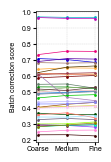

In [13]:
label_order = ['broad_cell_type', 'coarse_cell_type', 'cell_type']

print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['BATCH'], df1[df1['LabelKey'] == 'coarse_cell_type']['BATCH']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['BATCH'], df1[df1['LabelKey'] == 'cell_type']['BATCH']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'coarse_cell_type']['BATCH'], df1[df1['LabelKey'] == 'cell_type']['BATCH'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'BATCH', 'Batch correction score', invert=False, show_legend=False)
#     plt.savefig('../publication_figures/neurips_bmmc_granularity_batch.svg', bbox_inches='tight')

    plt.show()

WilcoxonResult(statistic=np.float64(34.0), pvalue=np.float64(5.420588422566652e-08)) WilcoxonResult(statistic=np.float64(1.0), pvalue=np.float64(2.9103830456733704e-11)) WilcoxonResult(statistic=np.float64(63.0), pvalue=np.float64(1.994820195250213e-06))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


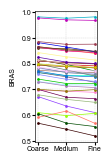

In [14]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['BRAS'], df1[df1['LabelKey'] == 'coarse_cell_type']['BRAS']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['BRAS'], df1[df1['LabelKey'] == 'cell_type']['BRAS']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'coarse_cell_type']['BRAS'], df1[df1['LabelKey'] == 'cell_type']['BRAS'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'BRAS', 'BRAS', invert=False)
    ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
    
    plt.show()

WilcoxonResult(statistic=np.float64(300.0), pvalue=np.float64(0.4461299913964467)) WilcoxonResult(statistic=np.float64(314.0), pvalue=np.float64(0.5808596221904736)) WilcoxonResult(statistic=np.float64(107.0), pvalue=np.float64(0.00010420967009849846))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


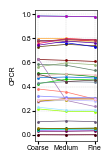

In [16]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['CPCR'], df1[df1['LabelKey'] == 'coarse_cell_type']['CPCR']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['CPCR'], df1[df1['LabelKey'] == 'cell_type']['CPCR']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'coarse_cell_type']['CPCR'], df1[df1['LabelKey'] == 'cell_type']['CPCR'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'CPCR', 'CPCR', invert=False)
    
    plt.show()

WilcoxonResult(statistic=np.float64(52.0), pvalue=np.float64(5.788315320387483e-07)) WilcoxonResult(statistic=np.float64(38.0), pvalue=np.float64(9.605719242244959e-08)) WilcoxonResult(statistic=np.float64(29.0), pvalue=np.float64(2.5305780582129955e-08))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


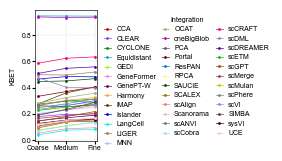

In [17]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['KBET'], df1[df1['LabelKey'] == 'coarse_cell_type']['KBET']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'broad_cell_type']['KBET'], df1[df1['LabelKey'] == 'cell_type']['KBET']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'coarse_cell_type']['KBET'], df1[df1['LabelKey'] == 'cell_type']['KBET'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'KBET', 'KBET', invert=False, show_legend=True)
#     plt.savefig('../publication_figures/neurips_bmmc_granularity_KBET.svg', bbox_inches='tight')

    plt.show()

### Human fetal gut

Data file: `../results/source_data/human_fetal_gut_granularity.csv`

In [11]:
recalcs = pd.concat([
    pd.read_csv('../results/granularity_ablation/human_fetal_gut_final_metrics_cpu_l1/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/human_fetal_gut_final_metrics_cpu_l2/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/human_fetal_gut_final_metrics_cpu_l3/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/human_fetal_gut_final_metrics_gpu_l1/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/human_fetal_gut_final_metrics_gpu_l2/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/human_fetal_gut_final_metrics_gpu_l3/metrics/all-metrics.csv'),
])
recalcs = recalcs[recalcs['Integration'].isin(['cyclone-1', 'scanvi-1', 'equidistant-1', 'scdml-1', 'islander-1'])]
origs = pd.read_csv('../results/granularity_ablation/human_fetal_gut_v3/metrics/all-metrics.csv')

df1 = pd.concat([recalcs, origs])
df1 = df1.drop_duplicates(['Dataset', "Integration", 'Metric', 'LabelKey'], keep='first')

In [12]:
df1 = df1.pivot(index=['Dataset', 'Integration', 'LabelKey'], columns='Metric', values='Value').reset_index()

In [13]:
df1['BIO'] = df1[['BAMI', 'CASW', 'SCGRAPHM']].mean(axis=1)
df1['BATCH'] = (df1['CPCR'] + df1['BRAS'] + df1['KBET']) / 3
df1['OVERALL'] = df1['BIO'] * .6 + df1['BATCH'] * .4

In [14]:
df1['Integration'] = df1['Integration'].str[:-2]

In [15]:
df1['Integration'] = df1["Integration"].replace(NAME_MAP)

In [16]:
df1.to_csv('../results/spreadsheets/human_fetal_gut_granularity.csv', index=False)

In [23]:
for k in ['BAMI', 'CASW', 'SCGRAPHM', 'KBET', 'CPCR', 'BRAS']:
    print(k)
    print('&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name'][k]).statistic, 3), '&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k]).statistic, 3), '&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_name'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k]).statistic, 3)
    )

BAMI
& 0.586 & 0.59 & 0.911
CASW
& 0.455 & 0.508 & 0.904
SCGRAPHM
& 0.073 & 0.116 & 0.893
KBET
& 0.868 & 0.79 & 0.9
CPCR
& 0.775 & 0.733 & 0.929
BRAS
& 0.579 & 0.608 & 0.893


/tmp/ipykernel_3354098/2014738233.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['Rank'] = df1.groupby(['LabelKey'])['OVERALL'].rank(ascending=False, method='min')
/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


SignificanceResult(statistic=np.float64(0.6648841354723708), pvalue=np.float64(3.2111302497211145e-08)) SignificanceResult(statistic=np.float64(0.6506238859180037), pvalue=np.float64(6.270114554414865e-08)) SignificanceResult(statistic=np.float64(0.8930481283422461), pvalue=np.float64(1.1104966149131675e-13))


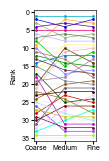

In [24]:
label_order = ['cell_type_group', 'cell_name', 'cell_name_detailed']
df1['LabelKey'] = pd.Categorical(df1['LabelKey'], categories=label_order, ordered=True)
df1['Rank'] = df1.groupby(['LabelKey'])['OVERALL'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group']['Rank'], df1[df1['LabelKey'] == 'cell_name']['Rank']),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group']['Rank'], df1[df1['LabelKey'] == 'cell_name_detailed']['Rank']),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_name']['Rank'], df1[df1['LabelKey'] == 'cell_name_detailed']['Rank'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'Rank', 'Rank', invert=True)

#     plt.savefig('../publication_figures/human_fetal_gut_granularity_rank.svg', bbox_inches='tight', transparent=True)
    plt.show()

WilcoxonResult(statistic=np.float64(214.0), pvalue=np.float64(0.15775297058280557)) WilcoxonResult(statistic=np.float64(292.0), pvalue=np.float64(0.9327671678038314)) WilcoxonResult(statistic=np.float64(69.0), pvalue=np.float64(2.8655631467700005e-05))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


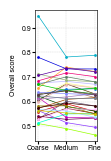

In [25]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group']['OVERALL'], df1[df1['LabelKey'] == 'cell_name']['OVERALL']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group']['OVERALL'], df1[df1['LabelKey'] == 'cell_name_detailed']['OVERALL']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_name']['OVERALL'], df1[df1['LabelKey'] == 'cell_name_detailed']['OVERALL'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'OVERALL', 'Overall score', invert=False)
    
#     plt.savefig('../publication_figures/human_fetal_gut_granularity_overall.svg', bbox_inches='tight', transparent=True)
    plt.show()

WilcoxonResult(statistic=np.float64(186.0), pvalue=np.float64(0.05704390583559871)) WilcoxonResult(statistic=np.float64(270.0), pvalue=np.float64(0.6484179915860295)) WilcoxonResult(statistic=np.float64(11.0), pvalue=np.float64(6.402842700481415e-09))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


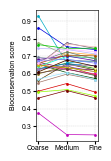

In [26]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group']['BIO'], df1[df1['LabelKey'] == 'cell_name']['BIO']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group']['BIO'], df1[df1['LabelKey'] == 'cell_name_detailed']['BIO']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_name']['BIO'], df1[df1['LabelKey'] == 'cell_name_detailed']['BIO'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'BIO', 'Bioconservation score', invert=False)
#     plt.savefig('../publication_figures/human_fetal_gut_granularity_bio.svg', bbox_inches='tight', transparent=True)
    plt.show()

WilcoxonResult(statistic=np.float64(285.0), pvalue=np.float64(0.8395236049545929)) WilcoxonResult(statistic=np.float64(251.0), pvalue=np.float64(0.43647122976835817)) WilcoxonResult(statistic=np.float64(154.0), pvalue=np.float64(0.013137052417732775))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


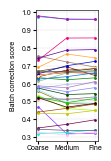

In [27]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group']['BATCH'], df1[df1['LabelKey'] == 'cell_name']['BATCH']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group']['BATCH'], df1[df1['LabelKey'] == 'cell_name_detailed']['BATCH']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_name']['BATCH'], df1[df1['LabelKey'] == 'cell_name_detailed']['BATCH'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'BATCH', 'Batch correction score', invert=False, show_legend=False, legend_ncols=9)
    
#     plt.savefig('../publication_figures/human_fetal_gut_granularity_batch.svg', bbox_inches='tight', transparent=True)
    plt.show()

/tmp/ipykernel_3354098/244306933.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['SCGRAPHM Rank'] = df1.groupby(['LabelKey'])['SCGRAPHM'].rank(ascending=False, method='min')


SignificanceResult(statistic=np.float64(0.07308377896613191), pvalue=np.float64(0.5433186857519277)) SignificanceResult(statistic=np.float64(0.11586452762923354), pvalue=np.float64(0.3352521161846773)) SignificanceResult(statistic=np.float64(0.8930481283422461), pvalue=np.float64(1.1104966149131675e-13))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


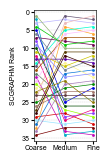

In [28]:
k = 'SCGRAPHM Rank'
df1['SCGRAPHM Rank'] = df1.groupby(['LabelKey'])['SCGRAPHM'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_name'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=True, show_legend=False)
    
#     plt.savefig(f'../publication_figures/human_fetal_gut_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

SignificanceResult(statistic=np.float64(0.5864527629233512), pvalue=np.float64(1.075795001942488e-06)) SignificanceResult(statistic=np.float64(0.590017825311943), pvalue=np.float64(9.25315447240252e-07)) SignificanceResult(statistic=np.float64(0.910873440285205), pvalue=np.float64(3.583248079917485e-14))


/tmp/ipykernel_3354098/2925195499.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['BAMI Rank'] = df1.groupby(['LabelKey'])['BAMI'].rank(ascending=False, method='min')
/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


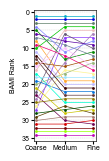

In [29]:
k = 'BAMI Rank'
df1['BAMI Rank'] = df1.groupby(['LabelKey'])['BAMI'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'cell_name'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=True, show_legend=False)
    
#     plt.savefig(f'../publication_figures/human_fetal_gut_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

WilcoxonResult(statistic=np.float64(24.0), pvalue=np.float64(4.581368063641844e-06)) WilcoxonResult(statistic=np.float64(178.0), pvalue=np.float64(0.06703303320262344)) WilcoxonResult(statistic=np.float64(1.0), pvalue=np.float64(5.91235537322886e-07))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


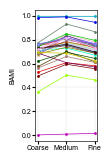

In [30]:
k = 'BAMI'
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_type_group'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'cell_name'][k], df1[df1['LabelKey'] == 'cell_name_detailed'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=False, show_legend=False)
    
#     plt.savefig(f'../publication_figures/human_fetal_gut_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

### Seurat PBMC

In [17]:
recalcs = pd.concat([
    pd.read_csv('../results/granularity_ablation/seurat_pbmc_final_metrics_cpu_l1/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/seurat_pbmc_final_metrics_cpu_l2/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/seurat_pbmc_final_metrics_cpu_l3/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/seurat_pbmc_final_metrics_gpu_l1/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/seurat_pbmc_final_metrics_gpu_l2/metrics/all-metrics.csv'),
    pd.read_csv('../results/granularity_ablation/seurat_pbmc_final_metrics_gpu_l3/metrics/all-metrics.csv'),
])
recalcs = recalcs[recalcs['Integration'].isin(['cyclone-1', 'scanvi-1', 'equidistant-1', 'scdml-1', 'islander-1'])]
origs = pd.read_csv('../results/granularity_ablation/seurat_pbmc_v3/metrics/all-metrics.csv')

df1 = pd.concat([recalcs, origs])
df1 = df1.drop_duplicates(['Dataset', "Integration", 'Metric', 'LabelKey'], keep='first')

In [18]:
df1 = df1.pivot(index=['Dataset', 'Integration', 'LabelKey'], columns='Metric', values='Value').reset_index()

In [19]:
df1['BIO'] = df1[['BAMI', 'CASW', 'SCGRAPHM', 'TRAJ']].mean(axis=1)
df1['BATCH'] = (df1['CPCR'] + df1['BRAS'] + df1['KBET']) / 3
df1['OVERALL'] = df1['BIO'] * .6 + df1['BATCH'] * .4

In [20]:
df1['Integration'] = df1['Integration'].str[:-2]

In [21]:
df1['Integration'] = df1["Integration"].replace(NAME_MAP)

In [24]:
df1.to_csv('../results/spreadsheets/seurat_pbmc_granularity.csv', index=False)

In [36]:
for k in ['BAMI', 'CASW', 'SCGRAPHM', 'TRAJ', 'KBET', 'CPCR', 'BRAS']:
    print(k)
    print('&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l2'][k]).statistic, 3), '&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]).statistic, 3), '&',
        np.round(scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l2'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]).statistic, 3)
    )

BAMI
& 0.7 & 0.691 & 0.943
CASW
& 0.772 & 0.709 & 0.865
SCGRAPHM
& 0.517 & 0.565 & 0.88
TRAJ
& -0.078 & -0.054 & 0.958
KBET
& 0.859 & 0.874 & 0.871
CPCR
& 0.91 & 0.856 & 0.94
BRAS
& 0.802 & 0.781 & 0.919


/tmp/ipykernel_3354098/3182921020.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['Rank'] = df1.groupby(['LabelKey'])['OVERALL'].rank(ascending=False, method='min')
/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


SignificanceResult(statistic=np.float64(0.4414414414414415), pvalue=np.float64(0.00012045853974286827)) SignificanceResult(statistic=np.float64(0.3963963963963964), pvalue=np.float64(0.0005547495209601937)) SignificanceResult(statistic=np.float64(0.912912912912913), pvalue=np.float64(1.8358388899482685e-15))


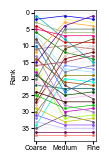

In [37]:
label_order = ['celltype_l1', 'celltype_l2', 'celltype_l3']
df1['LabelKey'] = pd.Categorical(df1['LabelKey'], categories=label_order, ordered=True)
df1['Rank'] = df1.groupby(['LabelKey'])['OVERALL'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1']['Rank'], df1[df1['LabelKey'] == 'celltype_l2']['Rank']),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1']['Rank'], df1[df1['LabelKey'] == 'celltype_l3']['Rank']),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l2']['Rank'], df1[df1['LabelKey'] == 'celltype_l3']['Rank'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'Rank', 'Rank', invert=True, show_legend=False)
#     plt.savefig('../publication_figures/seurat_pbmc_granularity_rank.svg', bbox_inches='tight')
    plt.show()

WilcoxonResult(statistic=np.float64(54.0), pvalue=np.float64(7.32092303223908e-07)) WilcoxonResult(statistic=np.float64(70.0), pvalue=np.float64(4.1184102883562446e-06)) WilcoxonResult(statistic=np.float64(305.0), pvalue=np.float64(0.49215231263951864))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


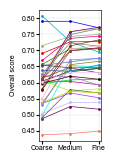

In [38]:
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1']['OVERALL'], df1[df1['LabelKey'] == 'celltype_l2']['OVERALL']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1']['OVERALL'], df1[df1['LabelKey'] == 'celltype_l3']['OVERALL']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l2']['OVERALL'], df1[df1['LabelKey'] == 'celltype_l3']['OVERALL'])
)
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'OVERALL', 'Overall score', invert=False, show_legend=False)
    
#     plt.savefig('../publication_figures/seurat_pbmc_granularity_overall.svg', bbox_inches='tight')
    plt.show()

WilcoxonResult(statistic=np.float64(242.0), pvalue=np.float64(0.10051859231316485)) WilcoxonResult(statistic=np.float64(297.0), pvalue=np.float64(0.4197080938902218)) WilcoxonResult(statistic=np.float64(40.0), pvalue=np.float64(1.264706952497363e-07))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


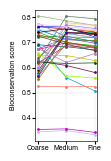

In [39]:
label_order = ['celltype_l1', 'celltype_l2', 'celltype_l3']

print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1']['BIO'], df1[df1['LabelKey'] == 'celltype_l2']['BIO']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1']['BIO'], df1[df1['LabelKey'] == 'celltype_l3']['BIO']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l2']['BIO'], df1[df1['LabelKey'] == 'celltype_l3']['BIO'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'BIO', 'Bioconservation score', invert=False, show_legend=False)
#     plt.savefig('../publication_figures/seurat_pbmc_granularity_bio.svg', bbox_inches='tight')

    plt.show()

WilcoxonResult(statistic=np.float64(5.0), pvalue=np.float64(1.4551915228366852e-10)) WilcoxonResult(statistic=np.float64(11.0), pvalue=np.float64(8.003553375601768e-10)) WilcoxonResult(statistic=np.float64(55.0), pvalue=np.float64(8.218921720981598e-07))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


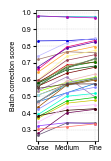

In [40]:
label_order = ['celltype_l1', 'celltype_l2', 'celltype_l3']

print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1']['BATCH'], df1[df1['LabelKey'] == 'celltype_l2']['BATCH']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1']['BATCH'], df1[df1['LabelKey'] == 'celltype_l3']['BATCH']),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l2']['BATCH'], df1[df1['LabelKey'] == 'celltype_l3']['BATCH'])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, 'BATCH', 'Batch correction score', invert=False, show_legend=False)
    
#     plt.savefig('../publication_figures/seurat_pbmc_granularity_batch.svg', bbox_inches='tight')

    plt.show()

WilcoxonResult(statistic=np.float64(68.0), pvalue=np.float64(3.3629185054451227e-06)) WilcoxonResult(statistic=np.float64(140.0), pvalue=np.float64(0.000996397517155856)) WilcoxonResult(statistic=np.float64(126.0), pvalue=np.float64(0.0004055113677168265))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


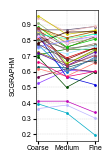

In [41]:
k = 'SCGRAPHM'
print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l2'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l2'][k], df1[df1['LabelKey'] == 'celltype_l3'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=False)
    plt.show()

/tmp/ipykernel_3354098/2589856151.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['SCGRAPHM Rank'] = df1.groupby(['LabelKey'])['SCGRAPHM'].rank(ascending=False, method='min')
/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


SignificanceResult(statistic=np.float64(0.5165165165165165), pvalue=np.float64(6.823047896101948e-06)) SignificanceResult(statistic=np.float64(0.5645645645645646), pvalue=np.float64(8.758516439363698e-07)) SignificanceResult(statistic=np.float64(0.8798798798798799), pvalue=np.float64(1.7991512842727367e-14))


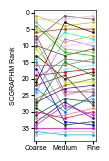

In [42]:
k = 'SCGRAPHM Rank'
df1['SCGRAPHM Rank'] = df1.groupby(['LabelKey'])['SCGRAPHM'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l2'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l2'][k], df1[df1['LabelKey'] == 'celltype_l3'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=True, show_legend=False)
    
#     plt.savefig(f'../publication_figures/seurat_pbmc_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

SignificanceResult(statistic=np.float64(0.6996996996996997), pvalue=np.float64(1.0960269692717793e-09)) SignificanceResult(statistic=np.float64(0.6906906906906908), pvalue=np.float64(1.7846487538747607e-09)) SignificanceResult(statistic=np.float64(0.942942942942943), pvalue=np.float64(2.147658199297534e-16))


/tmp/ipykernel_3354098/1301220112.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['BAMI Rank'] = df1.groupby(['LabelKey'])['BAMI'].rank(ascending=False, method='min')
/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


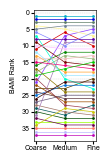

In [43]:
k = 'BAMI Rank'
df1['BAMI Rank'] = df1.groupby(['LabelKey'])['BAMI'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l2'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l2'][k], df1[df1['LabelKey'] == 'celltype_l3'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=True, show_legend=False)
    
#     plt.savefig(f'../publication_figures/seurat_pbmc_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

/tmp/ipykernel_3354098/312983393.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1['CASW Rank'] = df1.groupby(['LabelKey'])['CASW'].rank(ascending=False, method='min')
/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


SignificanceResult(statistic=np.float64(0.7717717717717718), pvalue=np.float64(1.7857764615639432e-11)) SignificanceResult(statistic=np.float64(0.7087087087087087), pvalue=np.float64(6.690795356870781e-10)) SignificanceResult(statistic=np.float64(0.8648648648648649), pvalue=np.float64(4.942240688409104e-14))


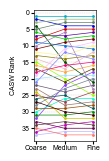

In [44]:
k = 'CASW Rank'
df1['CASW Rank'] = df1.groupby(['LabelKey'])['CASW'].rank(ascending=False, method='min')

print(
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l2'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]),
    scipy.stats.kendalltau(df1[df1['LabelKey'] == 'celltype_l2'][k], df1[df1['LabelKey'] == 'celltype_l3'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=True, show_legend=False)
    
#     plt.savefig(f'../publication_figures/seurat_pbmc_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

WilcoxonResult(statistic=np.float64(210.0), pvalue=np.float64(0.05331006569764642)) WilcoxonResult(statistic=np.float64(54.0), pvalue=np.float64(1.16921589696775e-05)) WilcoxonResult(statistic=np.float64(3.0), pvalue=np.float64(2.1660708397295836e-07))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


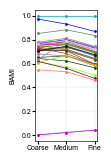

In [45]:
k = 'BAMI'

print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l2'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l2'][k], df1[df1['LabelKey'] == 'celltype_l3'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=False, show_legend=False)
    
#     plt.savefig(f'../publication_figures/seurat_pbmc_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

WilcoxonResult(statistic=np.float64(42.0), pvalue=np.float64(0.0002461822175086417)) WilcoxonResult(statistic=np.float64(32.0), pvalue=np.float64(9.863987574303977e-05)) WilcoxonResult(statistic=np.float64(4.0), pvalue=np.float64(0.7150006546880893))


/tmp/ipykernel_3354098/1501206642.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])


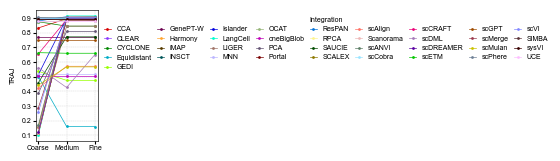

In [46]:
k = 'TRAJ'

print(
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l2'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l1'][k], df1[df1['LabelKey'] == 'celltype_l3'][k]),
    scipy.stats.wilcoxon(df1[df1['LabelKey'] == 'celltype_l2'][k], df1[df1['LabelKey'] == 'celltype_l3'][k])
)

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df1, k, k, invert=False, show_legend=True, legend_ncols=9)
    
#     plt.savefig(f'../publication_figures/seurat_pbmc_granularity_{k}.svg', bbox_inches='tight', transparent=True)
    plt.show()

## Investigate particular integrations

Why does the trajectory have weird behavior

In [47]:
# Load the HTML file
def load_html(file_path):
    with open(file_path, 'r') as f:
        html_content = f.read()

    soup = BeautifulSoup(html_content, 'html.parser')
    script_tags = soup.find_all('script')

    task_data = None
    for tag in script_tags:
        if tag.string and 'window.data =' in tag.string:
            match = re.search(r'window\.data\s*=\s*(\{.*?\});', tag.string, re.DOTALL)
            if match:
                json_text = match.group(1)
                json_text = re.sub(r'\\(?!["\\/bfnrtu])', r'\\\\', json_text)
                task_data = json.loads(json_text)
                break

    if task_data and 'trace' in task_data:
        df = pd.DataFrame(task_data['trace'])
        result_df = df[['name', 'workdir', 'status', 'peak_rss', 'duration']]
        return result_df
    else:
        print("Could not find task data in the HTML file.")
        return None

In [48]:
runs = pd.read_csv('../results/spreadsheets/all_integrations.csv')

In [49]:
adata = sc.read('../data/seurat_pbmc.h5ad')

In [50]:
method = 'scvi'
d = runs[runs.name.str.contains('seurat_pbmc') & runs.name.str.contains(method)].iloc[0]['workdir']
print(d)
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[-11]

if adata_int.X is None:
    adata_int = ad.AnnData(
        X=adata.X,
        obs=adata_int.obs,
        var=adata.var,
        uns=adata_int.uns,
        obsm=adata_int.obsm,
        varm=adata_int.varm,
        obsp=adata_int.obsp,
        varp=adata.varp,
        layers=adata.layers,
)

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/df/6e9620a7f3f4103844c545fec54dec


In [51]:
adata_int.obs['celltype.l1'] = adata.obs['celltype.l1']

In [ ]:
sc.pl.umap(adata, color=['dpt_pseudotime', 'celltype.l1'])

In [ ]:
sc.pl.umap(adata_int, color='celltype.l1')

In [54]:
pseudotime_key = 'dpt_pseudotime'
cell_subset = adata.obs.index[adata.obs[pseudotime_key].notnull()]
adata_pre_ti = adata[cell_subset]
adata_post_ti = adata_int[cell_subset]

In [55]:
iroot, adata_post_ti2 = scib.metrics.trajectory.get_root(
    adata_pre_ti, adata_post_ti, 'celltype.l1', pseudotime_key
)

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:120: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  n_components, adata_post.obs["neighborhood"] = connected_components(
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:125: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis


In [56]:
# l2 root is: 35036
iroot

33629

In [57]:
adata_post_ti2.obs.iloc[iroot]

donor                P7
celltype.l2     CD4 TEM
celltype_l2     CD4 TEM
cluster_0.2           3
cluster_0.4           8
cluster_0.6           9
cluster_0.8           7
cluster_1.0          10
cluster_1.2           9
cluster_1.4          10
cluster_1.6          12
cluster_1.8          10
cluster_2.0          14
celltype.l1       CD4 T
neighborhood          0
Name: E2L5_TTGACCCTCCACGAAT, dtype: object

In [59]:
adata_post_ti2.uns["iroot"] = iroot

sc.tl.dpt(adata_post_ti2)  # stored in 'dpt_pseudotime'
adata_post_ti2.obs.loc[
    adata_post_ti2.obs["dpt_pseudotime"] > 1, "dpt_pseudotime"
] = 0
adata_post_ti.obs["dpt_pseudotime"] = 0
adata_post_ti.obs["dpt_pseudotime"] = adata_post_ti2.obs["dpt_pseudotime"]
adata_post_ti.obs["dpt_pseudotime"].fillna(0, inplace=True)

/tmp/ipykernel_3354098/2331988397.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata_post_ti.obs["dpt_pseudotime"].fillna(0, inplace=True)


In [ ]:
sc.pl.umap(adata_post_ti2, color=['dpt_pseudotime', 'celltype.l1'])

In [61]:
pseudotime_before = adata_pre_ti.obs[pseudotime_key]
pseudotime_after = adata_post_ti.obs["dpt_pseudotime"]
correlation = pseudotime_before.corr(pseudotime_after, "spearman")
(correlation + 1) / 2  # scaled

# l2: np.float64(0.9025374289974082)

np.float64(0.20409436235283734)

In [126]:
fetal_gut = sc.read('../data/human_fetal_gut.h5ad')

In [127]:
fetal_gut.obs['cell_type_group'].nunique(), fetal_gut.obs['cell_name'].nunique(), fetal_gut.obs['cell_name_detailed'].nunique()

(4, 21, 28)

In [129]:
seurat_pbmc = sc.read('../data/seurat_pbmc.h5ad')

In [130]:
seurat_pbmc.obs['celltype.l1'].nunique(), seurat_pbmc.obs['celltype.l2'].nunique(), seurat_pbmc.obs['celltype.l3'].nunique()

(8, 31, 58)

In [131]:
neurips_bmmc = sc.read('../data/neurips_bmmc.h5ad')

In [132]:
neurips_bmmc.obs['broad_cell_type'].nunique(), neurips_bmmc.obs['coarse_cell_type'].nunique(), neurips_bmmc.obs['cell_type'].nunique()

(24, 34, 45)

## Individual metrics analysis

In [62]:
def compute_w_across_integrations(df):
    rank_df = df.copy()
    rank_df['Rank'] = rank_df.groupby(['Metric', 'LabelKey'])['Value'].rank(ascending=False, method='average')
    
    results = []
    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

### Seurat PBMC

Data file: `../results/source_data/seurat_pbmc_granularity_all_metrics.csv`

In [26]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/seurat_pbmc/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/seurat_pbmc_recalc/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/seurat_pbmc_rescue/metrics/all-metrics.csv')
df4 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/seurat_pbmc_recalc2/metrics/all-metrics.csv')

In [28]:
df = pd.concat([df, df2, df3, df4])
df = df.drop_duplicates(
    subset=["Metric", "Dataset", "Integration", "LabelKey"],keep='last'
)

# Flip the sign of these metrics
target_metrics = ['MIX', 'KLDIV', 'KNNDIV']
mask = df['Metric'].isin(target_metrics)

df.loc[mask, 'Value'] = df.loc[mask, 'Value'] * -1

In [29]:
target_labels = ['celltype_l1', 'celltype_l2', 'celltype_l3']

check_df = df.groupby(['Dataset', 'Integration', 'Metric', 'BatchKey']).agg(
    unique_values=('Value', 'nunique'),
    label_count=('LabelKey', 'nunique')
).reset_index()

check_df['is_consistent'] = (check_df['unique_values'] == 1) & (check_df['label_count'] == 3)

consistent_metrics = check_df.groupby('Metric')['is_consistent'].all()
consistent_metrics = consistent_metrics[consistent_metrics].index.tolist()

print("Metrics with same values across all celltype levels:")
print(consistent_metrics)

Metrics with same values across all celltype levels:
['ADGBD', 'AGREE', 'ALIGN', 'BATCHARI', 'BCENTROPY', 'BNENTROPY', 'BNENTROPYW', 'BPS', 'CBE', 'CH', 'CLUSTASW', 'CLUSTDBI', 'COMPACT', 'CORRMSE', 'CSMC', 'ILISI', 'KBETALL', 'KLDIV', 'LDFDIFF', 'MIX', 'MODULARITY', 'PROBE', 'RKNN', 'SEPARATION', 'SV']


In [30]:
df = df[~df['Metric'].isin(consistent_metrics)]

In [31]:
df = df[~df['Value'].isna()]

In [32]:
df = df[~df['Metric'].isin(['ISOASW', 'ISOF1', 'PROBEMIN'])]

In [33]:
# Rename metrics
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH'
})

In [34]:
df['Integration'] = df['Integration'].str[:-2]
df['Integration'] = df['Integration'].replace(NAME_MAP)

In [37]:
df.to_csv('../results/spreadsheets/seurat_pbmc_granularity_all_metrics.csv', index=False)

In [ ]:
label_order = ['celltype_l1', 'celltype_l2', 'celltype_l3']
df['LabelKey'] = pd.Categorical(df['LabelKey'], categories=label_order, ordered=True)

df['Rank'] = df.groupby(['Metric', 'LabelKey'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='LabelKey',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Resolution', fontsize=5)
        ax.set_xticks(range(len(label_order)))

        ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

#     plt.tight_layout()
#     plt.savefig('../publication_figures/seurat_pbmc_individual_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
label_order = ['celltype_l1', 'celltype_l2', 'celltype_l3']
df['LabelKey'] = pd.Categorical(df['LabelKey'], categories=label_order, ordered=True)

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):

    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=False)

    axes = axes.ravel()

    unique_integrations = df['Integration'].unique()
    color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

    plt.subplots_adjust(right=0.82, wspace=0.35, hspace=0.3) 
    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='LabelKey',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Resolution', fontsize=5)
        ax.set_xticks(range(len(label_order)))

        ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])
        if metric == 'CCH':
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.45, 0.02),
        ncols=11,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )
    

    plt.savefig('../publication_figures/seurat_pbmc_individual_metrics_values.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
l2_values = df[df['LabelKey'] == 'celltype_l2'][['Metric', 'Integration', 'Value']]
l2_values = l2_values.rename(columns={'Value': 'l2_Value'})

df_delta = df.merge(l2_values, on=['Metric', 'Integration'])
df_delta['RelativeValue'] = df_delta['Value'] - df_delta['l2_Value']

NUM_COLS = 6
metrics = df_delta['Metric'].unique()
num_rows = math.ceil(len(metrics) / NUM_COLS)

fig_width = NUM_COLS * 4 
fig_height = num_rows * 4.5
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=False)
axes = axes.ravel()

unique_ints = df_delta['Integration'].unique()
color_map = dict(zip(unique_ints, sns.color_palette("turbo", len(unique_ints))))

plt.subplots_adjust(right=0.85, wspace=0.35, hspace=0.4) 

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_delta[df_delta['Metric'] == metric]
    
    sns.lineplot(
        data=subset, 
        x='LabelKey', 
        y='RelativeValue', 
        hue='Integration', 
        marker='o', 
        markersize=8,
        linewidth=2, 
        palette=color_map, 
        ax=ax,
        legend=False
    )
    
    ax.axhline(0, color='black', linewidth=1.5, linestyle='--', alpha=0.6)
    ax.set_title(f'Delta: {metric}', fontsize=16)
    ax.set_ylabel('Difference from L2', fontsize=12)
    if i % 6 != 0:
        ax.set_ylabel('')
    ax.set_xlabel('')
    ax.grid(True, axis='y', linestyle=':', alpha=0.5)

for j in range(len(metrics), len(axes)):
    fig.delaxes(axes[j])

plt.show()

In [86]:
compute_w_across_integrations(df)

/tmp/ipykernel_3354098/2129017225.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rank_df['Rank'] = rank_df.groupby(['Metric', 'LabelKey'])['Value'].rank(ascending=False, method='average')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pi

/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', colum

,Metric,Kendall_W
0,AMI,0.926453
1,ARI,0.918023
2,ARIF,0.965937
3,AWC,0.936147
4,BAMI,0.929930
5,BARI,0.878457
6,BASW,0.926453
7,BKNN,0.929561
8,BLOGREG,0.921739
9,BRAS,0.957589


In [87]:
vals = []
for metric in ordered_metrics:
    sub1 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'celltype_l1')].sort_values('Integration')
    sub2 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'celltype_l2')].sort_values('Integration')
    sub3 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'celltype_l3')].sort_values('Integration')
    x = scipy.stats.kendalltau(sub1['Rank'], sub2['Rank']).statistic
    y = scipy.stats.kendalltau(sub1['Rank'], sub3['Rank']).statistic
    z = scipy.stats.kendalltau(sub2['Rank'], sub3['Rank']).statistic
    
    vals.append([x, y, z])
    
vals = np.array(vals)
taus = pd.DataFrame(vals, index=ordered_metrics, columns=['A', 'B', 'C'])

/tmp/ipykernel_3354098/1719499342.py:65: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


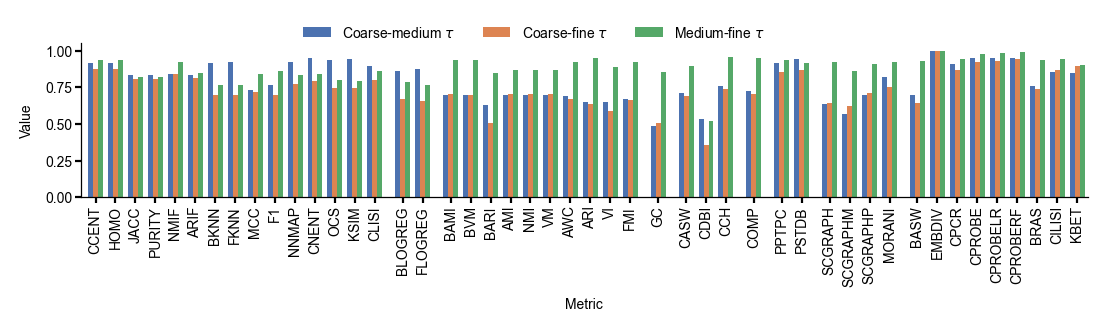

In [88]:
groups = [
    ["CCENT", "HOMO", "JACC", "PURITY", "NMIF", "ARIF", "BKNN", "FKNN", "MCC", "F1", "NNMAP", "CNENT", "OCS", "KSIM", "CLISI"],
    ["BLOGREG", "FLOGREG"],
    ["BAMI", "BVM", "BARI", "AMI", "NMI", "VM", "AWC", "ARI", "VI", "FMI"],
    ["GC"], ["CASW", "CDBI", "CCH"], ["COMP"],
    ["PPTPC", "PSTDB"], ["SCGRAPH", "SCGRAPHM", "SCGRAPHP", "MORANI"],
    ["BASW", "EMBDIV", "CPCR", "CPROBE", "CPROBELR", "CPROBERF", "BRAS", "CILISI", "KBET"],
]

bar_width = 0.25
within_group_gap = 1.0   # spacing between metrics within a group
between_group_gap = .4  # extra spacing added between groups

positions = []
labels = []
x = 0
for g_i, group in enumerate(groups):
    for metric in group:
        positions.append(x)
        labels.append(metric)
        x += within_group_gap
    x += between_group_gap

positions = np.array(positions)
colors = ["#4C72B0", "#DD8452", "#55A868"]

legend_labels = {
    "A": r"Coarse-medium $\tau$",
    "B": r"Coarse-fine $\tau$",
    "C": r"Medium-fine $\tau$",
}
with plt.rc_context({'figure.dpi': 200}):
    fig, ax = plt.subplots(figsize=(6.5, 1))
    for i, col in enumerate(taus.columns):
        values = [taus.loc[m, col] for m in labels]
        ax.bar(positions + i * bar_width, values, width=bar_width, label=legend_labels.get(col, col), color=colors[i])
 
    ax.set_title("")
    ax.set_xlabel("Metric", fontsize=5)
    ax.set_ylabel("Value", fontsize=5)
    
    ax.set_xticks(positions + bar_width)
    ax.set_xticklabels(labels, rotation=90)

    ax.set_ylim(0, 1.05)
    ax.set_xlim(-.5, 50)
    ax.legend(
        loc='upper center',
        ncols=3,
        title="",
        fontsize=5,
        title_fontsize=5,
        bbox_to_anchor=(0.45, 1.2),
        frameon=False
    )
    ax.spines[['top', 'right']].set_visible(False)

    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    plt.xticks(rotation=90)
    plt.tight_layout()
#     plt.savefig('../publication_figures/seurat_pbmc_all_metric_taus.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [89]:
cv_df = df.groupby(['Metric', 'LabelKey'])['Value'].agg(['std', 'mean']).reset_index()
cv_df.loc[cv_df['Metric'] == 'CDBI', 'mean'] = cv_df.loc[cv_df['Metric'] == 'CDBI', 'mean'] * -1
cv_df.loc[cv_df['Metric'] == 'EMBDIV', 'mean'] = cv_df.loc[cv_df['Metric'] == 'EMBDIV', 'mean'] * -1
cv_df['CV'] = cv_df['std'] / cv_df['mean']

label_order = ['celltype_l1', 'celltype_l2', 'celltype_l3']
cv_df['LabelKey'] = pd.Categorical(cv_df['LabelKey'], categories=label_order, ordered=True)
cv_df = cv_df.sort_values(['Metric', 'LabelKey'])

# plt.figure(figsize=(12, 7))
# sns.lineplot(
#     data=cv_df, 
#     x='LabelKey', 
#     y='CV', 
#     hue='Metric', 
#     marker='o', 
#     linewidth=2.5,
#     palette=sns.color_palette(cc.glasbey, n_colors=df['Metric'].nunique())
# )

# plt.title('Variability (CV) across Cell Type Granularity', fontsize=16)
# plt.ylabel('Coefficient of Variation (std / mean)', fontsize=14)
# plt.xlabel('Cell Type Level', fontsize=14)
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
# plt.tight_layout()

# plt.show()

/tmp/ipykernel_3354098/1471189104.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cv_df = df.groupby(['Metric', 'LabelKey'])['Value'].agg(['std', 'mean']).reset_index()


In [90]:
cv_df['LabelKey'] = pd.Categorical(cv_df['LabelKey'], categories=label_order, ordered=True)
cv_df = cv_df.sort_values(['Metric', 'LabelKey'])
cv_df['LabelKey'] = cv_df['LabelKey'].replace({
    'celltype_l1': 'Coarse',
    'celltype_l2': 'Medium',
    'celltype_l3': 'Fine'
})
label_order = ['Coarse', 'Medium', 'Fine']

/tmp/ipykernel_3354098/1070047326.py:3: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  cv_df['LabelKey'] = cv_df['LabelKey'].replace({


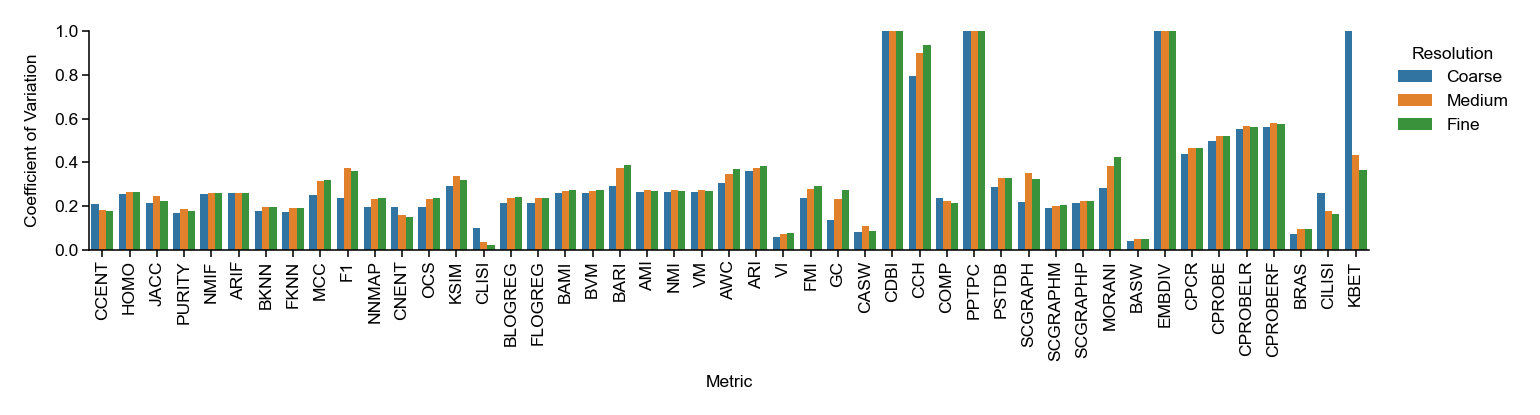

In [91]:
with plt.rc_context({'figure.dpi': 250}):
    plt.figure(figsize=(6.5, 2))
    
    ax = sns.barplot(
        data=cv_df,
        x='Metric',
        y='CV',
        hue='LabelKey',
        hue_order=label_order,
        order=ordered_metrics
    )
    ax.tick_params(
        axis='both', which='major', width=.45,
        length=2, labelsize=5, pad=1
    )
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.set_ylim(0, 1.0)
    # Manually annotate in post
#     for i, metric in enumerate(ordered_metrics):
#         for j, level in enumerate(label_order):
#             val = cv_df[(cv_df.Metric==metric) & (cv_df.LabelKey==level)]['CV'].values
#             if len(val) and val[0] > 1.0:
#                 ax.text(i + (j-1)*0.27, 0.95, f'{val[0]:.1f}', 
#                          ha='center', va='top', fontsize=4, rotation=90, color='white')
    ax.spines[['top', 'right']].set_visible(False)

    plt.ylabel('Coefficient of Variation', fontsize=5)
    plt.xlabel('Metric', fontsize=5)
    plt.xticks(rotation=90)
    plt.legend(title='Resolution', bbox_to_anchor=(1.01, 1), loc='upper left',fontsize=5,
            title_fontsize=5, frameon=False)
    plt.tight_layout()
#     plt.savefig('../publication_figures/seurat_pbmc_all_metric_cvs.png', dpi=300, bbox_inches='tight')
    plt.show()

In [92]:
cv_df[cv_df['CV'] >= 1]

,Metric,LabelKey,std,mean,CV
45,CDBI,Coarse,51.981355,13.928021,3.732142
46,CDBI,Medium,26.779894,8.878134,3.016388
47,CDBI,Fine,19.798990,9.944036,1.991042
78,EMBDIV,Coarse,49.694383,23.006570,2.160008
79,EMBDIV,Medium,49.694383,23.006570,2.160008
80,EMBDIV,Fine,49.693120,23.006064,2.160001
105,KBET,Coarse,0.200390,0.150071,1.335303
132,PPTPC,Coarse,0.181592,0.144963,1.252673
133,PPTPC,Medium,0.215431,0.173511,1.241602
134,PPTPC,Fine,0.171186,0.153172,1.117603


### Human fetal gut

Data file: `../results/source_data/human_fetal_gut_granularity_all_metrics.csv`

In [39]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/human_fetal_gut/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/human_fetal_gut_rescue/metrics/all-metrics.csv')
df3 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/human_fetal_gut_recalc/metrics/all-metrics.csv')

In [40]:
df = pd.concat([df, df2, df3])
df = df.drop_duplicates(
    subset=["Metric", "Dataset", "Integration", "LabelKey"],keep='last'  # Keep last means the most recent result will be stored.
)

target_metrics = ['MIX', 'KLDIV', 'KNNDIV']
mask = df['Metric'].isin(target_metrics)

# Multiply the 'Value' column by -1 only for rows matching the mask
df.loc[mask, 'Value'] = df.loc[mask, 'Value'] * -1

In [41]:
target_labels = ['cell_type_group', 'cell_name', 'cell_name_detailed']

check_df = df.groupby(['Dataset', 'Integration', 'Metric', 'BatchKey']).agg(
    unique_values=('Value', 'nunique'),
    label_count=('LabelKey', 'nunique')
).reset_index()

check_df['is_consistent'] = (check_df['unique_values'] == 1) & (check_df['label_count'] == 3)

consistent_metrics = check_df.groupby('Metric')['is_consistent'].all()
consistent_metrics = consistent_metrics[consistent_metrics].index.tolist()

print("Metrics with same values across all celltype levels:")
print(consistent_metrics)

Metrics with same values across all celltype levels:
['BNENTROPYW', 'KBETALL']


In [42]:
df = df[~df['Metric'].isin(consistent_metrics)]

In [43]:
df = df[~df['Value'].isna()]

In [44]:
df = df[~df['Metric'].isin(['ISOASW', 'ISOF1', 'PROBEMIN'])]

In [45]:
# Rename metrics
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH'
})

In [46]:
df['LabelKey'] = df['LabelKey'].replace({'cell_type_group': 'l1', 'cell_name': 'l2', 'cell_name_detailed': 'l3'})

In [47]:
df = df.reset_index(drop=True)

In [48]:
df['Integration'] = df['Integration'].str.split('-').str[0]
df['Integration'] = df['Integration'].replace(NAME_MAP)

In [51]:
df.to_csv('../results/spreadsheets/human_fetal_gut_granularity_all_metrics.csv', index=False)

In [ ]:
label_order = ['l1', 'l2', 'l3']
df['LabelKey'] = pd.Categorical(df['LabelKey'], categories=label_order, ordered=True)
df['Rank'] = df.groupby(['Metric', 'LabelKey'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='LabelKey',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Resolution', fontsize=5)
        ax.set_xticks(range(len(label_order)))

        ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

#     plt.tight_layout()
#     plt.savefig('../publication_figures/human_fetal_gut_individual_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
label_order = ['l1', 'l2', 'l3']
df['LabelKey'] = pd.Categorical(df['LabelKey'], categories=label_order, ordered=True)

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):

    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=False)

    axes = axes.ravel()

    unique_integrations = df['Integration'].unique()
    color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

    plt.subplots_adjust(right=0.82, wspace=0.35, hspace=0.3) 
    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='LabelKey',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Resolution', fontsize=5)
        ax.set_xticks(range(len(label_order)))

        ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])
        if metric == 'CCH':
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.45, 0.02),
        ncols=11,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )
    

    plt.savefig('../publication_figures/human_fetal_gut_individual_metrics_values.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
l2_values = df[df['LabelKey'] == 'l2'][['Metric', 'Integration', 'Value']]
l2_values = l2_values.rename(columns={'Value': 'l2_Value'})

df_delta = df.merge(l2_values, on=['Metric', 'Integration'])
df_delta['RelativeValue'] = df_delta['Value'] - df_delta['l2_Value']

NUM_COLS = 6
metrics = df_delta['Metric'].unique()
num_rows = math.ceil(len(metrics) / NUM_COLS)

fig_width = NUM_COLS * 4 
fig_height = num_rows * 4.5
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=False)
axes = axes.ravel()

unique_ints = df_delta['Integration'].unique()
color_map = dict(zip(unique_ints, sns.color_palette("turbo", len(unique_ints))))

plt.subplots_adjust(right=0.85, wspace=0.35, hspace=0.4) 

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_delta[df_delta['Metric'] == metric]
    
    sns.lineplot(
        data=subset, 
        x='LabelKey', 
        y='RelativeValue', 
        hue='Integration', 
        marker='o', 
        markersize=8,
        linewidth=2, 
        palette=color_map, 
        ax=ax,
        legend=False
    )
    
    ax.axhline(0, color='black', linewidth=1.5, linestyle='--', alpha=0.6)
    ax.set_title(f'Delta: {metric}', fontsize=16)
    ax.set_ylabel('Difference from L2', fontsize=12)
    if i % 6 != 0:
        ax.set_ylabel('')
    ax.set_xlabel('')
    ax.grid(True, axis='y', linestyle=':', alpha=0.5)

for j in range(len(metrics), len(axes)):
    fig.delaxes(axes[j])

plt.show()

In [104]:
w_results_2 = compute_w_across_integrations(df)
w_results_2['Dataset'] = 'human_fetal_gut'
w_results_2

/tmp/ipykernel_3354098/2129017225.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rank_df['Rank'] = rank_df.groupby(['Metric', 'LabelKey'])['Value'].rank(ascending=False, method='average')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pi

/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', colum

,Metric,Kendall_W,Dataset
0,AMI,0.793023,human_fetal_gut
1,ARI,0.709363,human_fetal_gut
2,ARIF,0.966758,human_fetal_gut
3,AWC,0.833087,human_fetal_gut
4,BAMI,0.871590,human_fetal_gut
5,BARI,0.825753,human_fetal_gut
6,BASW,0.811561,human_fetal_gut
7,BATCHARI,0.869824,human_fetal_gut
8,BCENT,0.865207,human_fetal_gut
9,BKNN,0.960139,human_fetal_gut


In [105]:
vals = []
for metric in ordered_metrics:
    sub1 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'l1')].sort_values('Integration')
    sub2 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'l2')].sort_values('Integration')
    sub3 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'l3')].sort_values('Integration')
    x = scipy.stats.kendalltau(sub1['Rank'], sub2['Rank']).statistic
    y = scipy.stats.kendalltau(sub1['Rank'], sub3['Rank']).statistic
    z = scipy.stats.kendalltau(sub2['Rank'], sub3['Rank']).statistic
    
    vals.append([x, y, z])
    
vals = np.array(vals)
taus = pd.DataFrame(vals, index=ordered_metrics, columns=['A', 'B', 'C'])

/tmp/ipykernel_3354098/2720992154.py:65: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


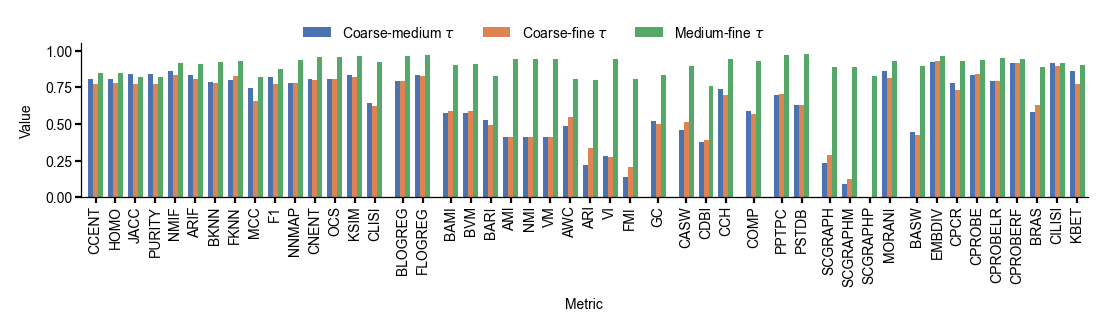

In [106]:
groups = [
    ["CCENT", "HOMO", "JACC", "PURITY", "NMIF", "ARIF", "BKNN", "FKNN", "MCC", "F1", "NNMAP", "CNENT", "OCS", "KSIM", "CLISI"],
    ["BLOGREG", "FLOGREG"],
    ["BAMI", "BVM", "BARI", "AMI", "NMI", "VM", "AWC", "ARI", "VI", "FMI"],
    ["GC"], ["CASW", "CDBI", "CCH"], ["COMP"],
    ["PPTPC", "PSTDB"], ["SCGRAPH", "SCGRAPHM", "SCGRAPHP", "MORANI"],
    ["BASW", "EMBDIV", "CPCR", "CPROBE", "CPROBELR", "CPROBERF", "BRAS", "CILISI", "KBET"],
]

bar_width = 0.25
within_group_gap = 1.0   # spacing between metrics within a group
between_group_gap = .4  # extra spacing added between groups

positions = []
labels = []
x = 0
for g_i, group in enumerate(groups):
    for metric in group:
        positions.append(x)
        labels.append(metric)
        x += within_group_gap
    x += between_group_gap

positions = np.array(positions)
colors = ["#4C72B0", "#DD8452", "#55A868"]

legend_labels = {
    "A": r"Coarse-medium $\tau$",
    "B": r"Coarse-fine $\tau$",
    "C": r"Medium-fine $\tau$",
}
with plt.rc_context({'figure.dpi': 200}):
    fig, ax = plt.subplots(figsize=(6.5, 1))
    for i, col in enumerate(taus.columns):
        values = [taus.loc[m, col] for m in labels]
        ax.bar(positions + i * bar_width, values, width=bar_width, label=legend_labels.get(col, col), color=colors[i])
 
    ax.set_title("")
    ax.set_xlabel("Metric", fontsize=5)
    ax.set_ylabel("Value", fontsize=5)
    
    ax.set_xticks(positions + bar_width)
    ax.set_xticklabels(labels, rotation=90)

    ax.set_ylim(0, 1.05)
    ax.set_xlim(-.5, 50)
    ax.legend(
        loc='upper center',
        ncols=3,
        title="",
        fontsize=5,
        title_fontsize=5,
        bbox_to_anchor=(0.45, 1.2),
        frameon=False
    )
    ax.spines[['top', 'right']].set_visible(False)

    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    plt.xticks(rotation=90)
    plt.tight_layout()
#     plt.savefig('../publication_figures/human_fetal_gut_all_metric_taus.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [107]:
cv_df = df[df['Metric'].isin(ordered_metrics)].groupby(['Metric', 'LabelKey'])['Value'].agg(['std', 'mean']).reset_index()
cv_df.loc[cv_df['Metric'] == 'CDBI', 'mean'] = cv_df.loc[cv_df['Metric'] == 'CDBI', 'mean'] * -1
cv_df['CV'] = cv_df['std'] / cv_df['mean']
# cv_df['CV'] = np.log(cv_df['CV'])

label_order = ['l1', 'l2', 'l3']
cv_df['LabelKey'] = pd.Categorical(cv_df['LabelKey'], categories=label_order, ordered=True)
cv_df = cv_df.sort_values(['Metric', 'LabelKey'])

# plt.figure(figsize=(12, 7))
# sns.lineplot(
#     data=cv_df, 
#     x='LabelKey', 
#     y='CV', 
#     hue='Metric',
#     hue_order=ordered_metrics,
#     marker='o', 
#     linewidth=2.5,
#     palette=sns.color_palette(cc.glasbey, n_colors=df['Metric'].nunique()) # Or any other high-contrast palette
# )

# plt.title('Variability (CV) across Cell Type Granularity', fontsize=16)
# plt.ylabel('Coefficient of Variation (std / mean)', fontsize=14)
# plt.xlabel('Cell Type Level', fontsize=14)
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
# plt.tight_layout()

# plt.show()

/tmp/ipykernel_3354098/2720526992.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cv_df = df[df['Metric'].isin(ordered_metrics)].groupby(['Metric', 'LabelKey'])['Value'].agg(['std', 'mean']).reset_index()


In [108]:
cv_df['LabelKey'] = pd.Categorical(cv_df['LabelKey'], categories=label_order, ordered=True)
cv_df = cv_df.sort_values(['Metric', 'LabelKey'])
cv_df['LabelKey'] = cv_df['LabelKey'].replace({
    'l1': 'Coarse',
    'l2': 'Medium',
    'l3': 'Fine'
})
label_order = ['Coarse', 'Medium', 'Fine']

/tmp/ipykernel_3354098/2899413635.py:3: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  cv_df['LabelKey'] = cv_df['LabelKey'].replace({


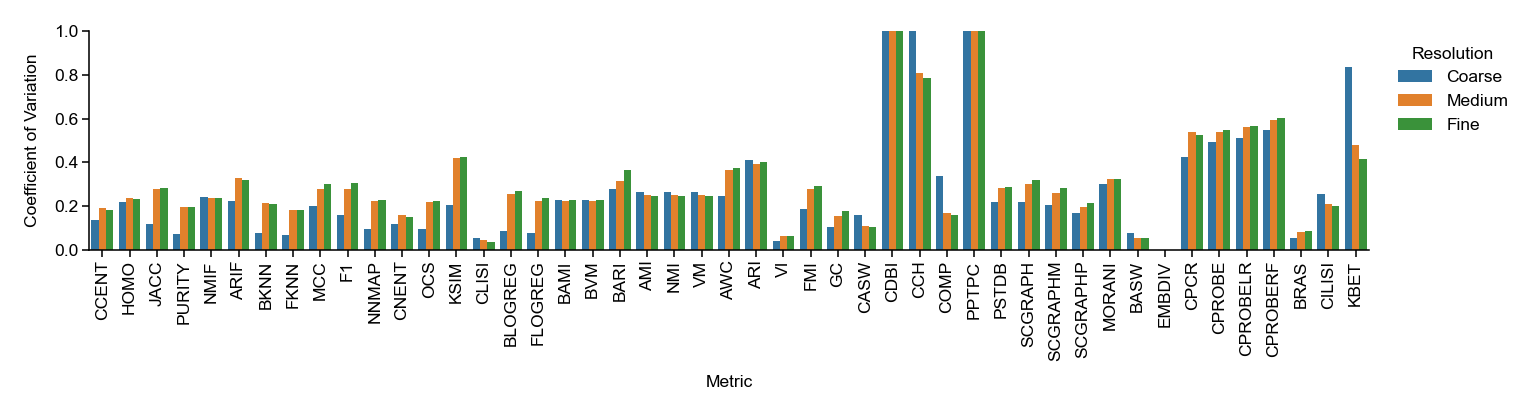

In [109]:
with plt.rc_context({'figure.dpi': 250}):
    plt.figure(figsize=(6.5, 2))
    
    ax = sns.barplot(
        data=cv_df,
        x='Metric',
        y='CV',
        hue='LabelKey',
        hue_order=label_order,
        order=ordered_metrics
    )
    ax.tick_params(
        axis='both', which='major', width=.45,
        length=2, labelsize=5, pad=1
    )
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.set_ylim(0, 1.0)
    # Manually annotate in post
#     for i, metric in enumerate(ordered_metrics):
#         for j, level in enumerate(label_order):
#             val = cv_df[(cv_df.Metric==metric) & (cv_df.LabelKey==level)]['CV'].values
#             if len(val) and val[0] > 1.0:
#                 ax.text(i + (j-1)*0.27, 0.95, f'{val[0]:.1f}', 
#                          ha='center', va='top', fontsize=4, rotation=90, color='white')
    ax.spines[['top', 'right']].set_visible(False)

    plt.ylabel('Coefficient of Variation', fontsize=5)
    plt.xlabel('Metric', fontsize=5)
    plt.xticks(rotation=90)
    plt.legend(title='Resolution', bbox_to_anchor=(1.01, 1), loc='upper left',fontsize=5,
            title_fontsize=5, frameon=False)
    plt.tight_layout()
#     plt.savefig('../publication_figures/human_fetal_gut_all_metric_cvs.png', dpi=300, bbox_inches='tight')
    plt.show()

In [110]:
cv_df[cv_df['CV'] > 1]

,Metric,LabelKey,std,mean,CV
39,CCH,Coarse,81207.195706,27123.515768,2.993977
42,CDBI,Coarse,30.519932,7.149206,4.268996
43,CDBI,Medium,17.939037,5.820860,3.081853
44,CDBI,Fine,14.953531,5.332628,2.804158
117,PPTPC,Coarse,0.176623,0.138465,1.275576
118,PPTPC,Medium,0.176679,0.155545,1.135873
119,PPTPC,Fine,0.176276,0.153895,1.145424


### NeurIPS BMMC

Data file: `../results/source_data/neurips_bmmc_granularity_all_metrics.csv`

In [52]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/neurips_bmmc/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/granularity_ablation/neurips_bmmc_recalc/metrics/all-metrics.csv')

In [53]:
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Metric", "Dataset", "Integration", "LabelKey"],keep='last'  # Keep last means the most recent result will be stored.
)
target_metrics = ['MIX', 'KLDIV', 'KNNDIV']
mask = df['Metric'].isin(target_metrics)

df.loc[mask, 'Value'] = df.loc[mask, 'Value'] * -1

In [54]:
target_labels = ['cell_type_group', 'cell_name', 'cell_name_detailed']

check_df = df.groupby(['Dataset', 'Integration', 'Metric', 'BatchKey']).agg(
    unique_values=('Value', 'nunique'),
    label_count=('LabelKey', 'nunique')
).reset_index()

check_df['is_consistent'] = (check_df['unique_values'] == 1) & (check_df['label_count'] == 3)

consistent_metrics = check_df.groupby('Metric')['is_consistent'].all()
consistent_metrics = consistent_metrics[consistent_metrics].index.tolist()

print("Metrics with same values across all celltype levels:")
print(consistent_metrics)

Metrics with same values across all celltype levels:
[]


In [56]:
df = df[~df['Metric'].isin(consistent_metrics)]

In [57]:
df = df[~df['Value'].isna()]

In [58]:
df = df[~df['Metric'].isin(['ISOASW', 'ISOF1', 'PROBEMIN'])]

In [59]:
# Rename metrics
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH'
})

In [60]:
df['LabelKey'] = df['LabelKey'].replace({'broad_cell_type': 'l1', 'coarse_cell_type': 'l2', 'cell_type': 'l3'})

In [61]:
df = df.reset_index(drop=True)

In [62]:
df['Integration'] = df['Integration'].str.split('-').str[0]
df['Integration'] = df['Integration'].replace(NAME_MAP)

In [63]:
df.to_csv('../results/spreadsheets/neurips_bmmc_granularity_all_metrics.csv', index=False)

In [ ]:
label_order = ['l1', 'l2', 'l3']
df['LabelKey'] = pd.Categorical(df['LabelKey'], categories=label_order, ordered=True)
df['Rank'] = df.groupby(['Metric', 'LabelKey'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='LabelKey',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Resolution', fontsize=5)
        ax.set_xticks(range(len(label_order)))

        ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

#     plt.tight_layout()
#     plt.savefig('../publication_figures/neurips_bmmc_individual_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
label_order = ['l1', 'l2', 'l3']
df['LabelKey'] = pd.Categorical(df['LabelKey'], categories=label_order, ordered=True)

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):

    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=False)

    axes = axes.ravel()

    unique_integrations = df['Integration'].unique()
    color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

    plt.subplots_adjust(right=0.82, wspace=0.35, hspace=0.3) 
    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='LabelKey',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Resolution', fontsize=5)
        ax.set_xticks(range(len(label_order)))

        ax.set_xticklabels(['Coarse', 'Medium', 'Fine'])
        if metric == 'CCH':
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.45, 0.02),
        ncols=11,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )
    

    plt.savefig('../publication_figures/neurips_bmmc_individual_metrics_values.png', dpi=300, bbox_inches='tight')
    plt.show()

In [122]:
w_results_3 = compute_w_across_integrations(df)
w_results_3['Dataset'] = 'neurips_bmmc'
w_results_3

/tmp/ipykernel_3354098/2129017225.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rank_df['Rank'] = rank_df.groupby(['Metric', 'LabelKey'])['Value'].rank(ascending=False, method='average')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pi

/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', columns='LabelKey', values='Rank', aggfunc='first')
/tmp/ipykernel_3354098/2129017225.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = group.pivot_table(index='Integration', colum

,Metric,Kendall_W,Dataset
0,ADGBD,0.983246,neurips_bmmc
1,AGREE,0.999473,neurips_bmmc
2,ALIGN,0.981929,neurips_bmmc
3,AMI,0.964860,neurips_bmmc
4,ARI,0.941152,neurips_bmmc
...,...,...,...
71,SCGRAPHP,0.976345,neurips_bmmc
72,SEPARATION,1.000000,neurips_bmmc
73,SV,0.998209,neurips_bmmc
74,VI,0.971498,neurips_bmmc


In [123]:
vals = []
for metric in ordered_metrics:
    sub1 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'l1')].sort_values('Integration')
    sub2 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'l2')].sort_values('Integration')
    sub3 = df[(df['Metric'] == metric) & (df['LabelKey'] == 'l3')].sort_values('Integration')
    x = scipy.stats.kendalltau(sub1['Rank'], sub2['Rank']).statistic
    y = scipy.stats.kendalltau(sub1['Rank'], sub3['Rank']).statistic
    z = scipy.stats.kendalltau(sub2['Rank'], sub3['Rank']).statistic
    
    vals.append([x, y, z])
    
vals = np.array(vals)
taus = pd.DataFrame(vals, index=ordered_metrics, columns=['A', 'B', 'C'])

/tmp/ipykernel_3354098/827074632.py:65: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


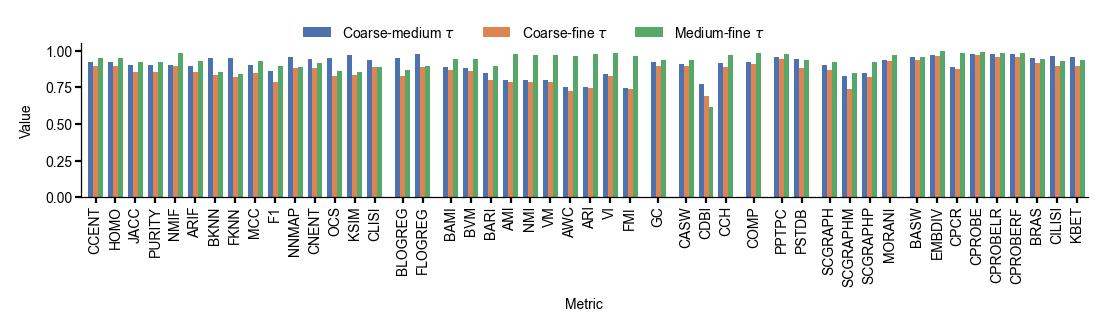

In [124]:
groups = [
    ["CCENT", "HOMO", "JACC", "PURITY", "NMIF", "ARIF", "BKNN", "FKNN", "MCC", "F1", "NNMAP", "CNENT", "OCS", "KSIM", "CLISI"],
    ["BLOGREG", "FLOGREG"],
    ["BAMI", "BVM", "BARI", "AMI", "NMI", "VM", "AWC", "ARI", "VI", "FMI"],
    ["GC"], ["CASW", "CDBI", "CCH"], ["COMP"],
    ["PPTPC", "PSTDB"], ["SCGRAPH", "SCGRAPHM", "SCGRAPHP", "MORANI"],
    ["BASW", "EMBDIV", "CPCR", "CPROBE", "CPROBELR", "CPROBERF", "BRAS", "CILISI", "KBET"],
]

bar_width = 0.25
within_group_gap = 1.0   # spacing between metrics within a group
between_group_gap = .4  # extra spacing added between groups

positions = []
labels = []
x = 0
for g_i, group in enumerate(groups):
    for metric in group:
        positions.append(x)
        labels.append(metric)
        x += within_group_gap
    x += between_group_gap

positions = np.array(positions)
colors = ["#4C72B0", "#DD8452", "#55A868"]

legend_labels = {
    "A": r"Coarse-medium $\tau$",
    "B": r"Coarse-fine $\tau$",
    "C": r"Medium-fine $\tau$",
}
with plt.rc_context({'figure.dpi': 200}):
    fig, ax = plt.subplots(figsize=(6.5, 1))
    for i, col in enumerate(taus.columns):
        values = [taus.loc[m, col] for m in labels]
        ax.bar(positions + i * bar_width, values, width=bar_width, label=legend_labels.get(col, col), color=colors[i])
 
    ax.set_title("")
    ax.set_xlabel("Metric", fontsize=5)
    ax.set_ylabel("Value", fontsize=5)
    
    ax.set_xticks(positions + bar_width)
    ax.set_xticklabels(labels, rotation=90)

    ax.set_ylim(0, 1.05)
    ax.set_xlim(-.5, 50)
    ax.legend(
        loc='upper center',
        ncols=3,
        title="",
        fontsize=5,
        title_fontsize=5,
        bbox_to_anchor=(0.45, 1.2),
        frameon=False
    )
    ax.spines[['top', 'right']].set_visible(False)

    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    plt.xticks(rotation=90)
    plt.tight_layout()
#     plt.savefig('../publication_figures/neurips_bmmc_all_metric_taus.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [125]:
cv_df = df[df['Metric'].isin(ordered_metrics)].groupby(['Metric', 'LabelKey'])['Value'].agg(['std', 'mean']).reset_index()
cv_df.loc[cv_df['Metric'] == 'CDBI', 'mean'] = cv_df.loc[cv_df['Metric'] == 'CDBI', 'mean'] * -1
cv_df['CV'] = cv_df['std'] / cv_df['mean']
# cv_df['CV'] = np.log(cv_df['CV'])

label_order = ['l1', 'l2', 'l3']
cv_df['LabelKey'] = pd.Categorical(cv_df['LabelKey'], categories=label_order, ordered=True)
cv_df = cv_df.sort_values(['Metric', 'LabelKey'])

# plt.figure(figsize=(12, 7))
# sns.lineplot(
#     data=cv_df, 
#     x='LabelKey', 
#     y='CV', 
#     hue='Metric',
#     hue_order=ordered_metrics,
#     marker='o', 
#     linewidth=2.5,
#     palette=sns.color_palette(cc.glasbey, n_colors=df['Metric'].nunique()) # Or any other high-contrast palette
# )

# plt.title('Variability (CV) across Cell Type Granularity', fontsize=16)
# plt.ylabel('Coefficient of Variation (std / mean)', fontsize=14)
# plt.xlabel('Cell Type Level', fontsize=14)
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
# plt.tight_layout()

# plt.show()

/tmp/ipykernel_3354098/2720526992.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cv_df = df[df['Metric'].isin(ordered_metrics)].groupby(['Metric', 'LabelKey'])['Value'].agg(['std', 'mean']).reset_index()


In [126]:
cv_df['LabelKey'] = pd.Categorical(cv_df['LabelKey'], categories=label_order, ordered=True)
cv_df = cv_df.sort_values(['Metric', 'LabelKey'])
cv_df['LabelKey'] = cv_df['LabelKey'].replace({
    'l1': 'Coarse',
    'l2': 'Medium',
    'l3': 'Fine'
})
label_order = ['Coarse', 'Medium', 'Fine']

/tmp/ipykernel_3354098/2899413635.py:3: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  cv_df['LabelKey'] = cv_df['LabelKey'].replace({


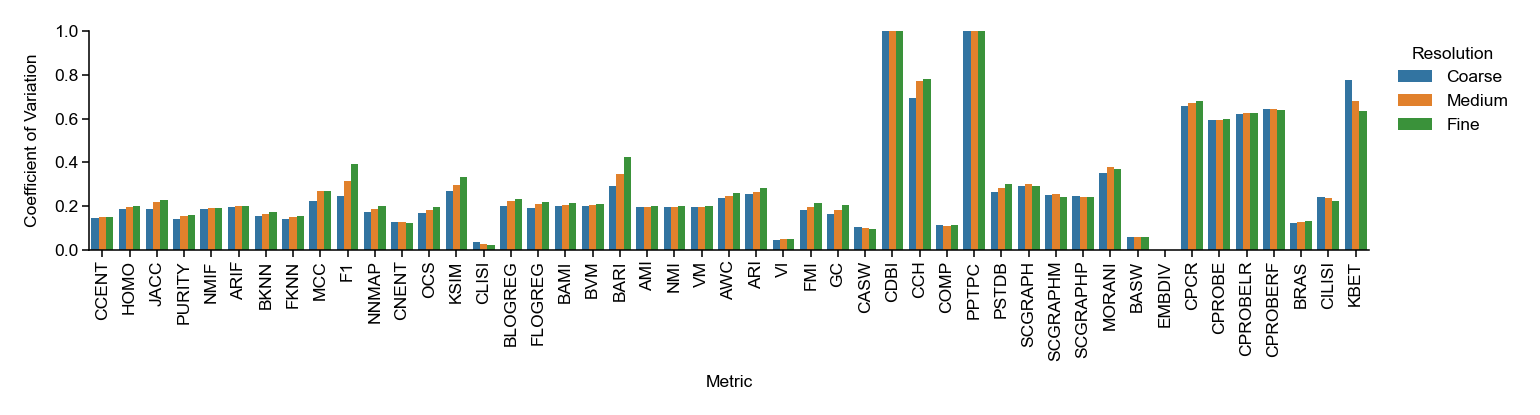

In [127]:
with plt.rc_context({'figure.dpi': 250}):
    plt.figure(figsize=(6.5, 2))
    
    ax = sns.barplot(
        data=cv_df,
        x='Metric',
        y='CV',
        hue='LabelKey',
        hue_order=label_order,
        order=ordered_metrics
    )
    ax.tick_params(
        axis='both', which='major', width=.45,
        length=2, labelsize=5, pad=1
    )
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.set_ylim(0, 1.0)
    # Manually annotate in post
#     for i, metric in enumerate(ordered_metrics):
#         for j, level in enumerate(label_order):
#             val = cv_df[(cv_df.Metric==metric) & (cv_df.LabelKey==level)]['CV'].values
#             if len(val) and val[0] > 1.0:
#                 ax.text(i + (j-1)*0.27, 0.95, f'{val[0]:.1f}', 
#                          ha='center', va='top', fontsize=4, rotation=90, color='white')
    ax.spines[['top', 'right']].set_visible(False)

    plt.ylabel('Coefficient of Variation', fontsize=5)
    plt.xlabel('Metric', fontsize=5)
    plt.xticks(rotation=90)
    plt.legend(title='Resolution', bbox_to_anchor=(1.01, 1), loc='upper left',fontsize=5,
            title_fontsize=5, frameon=False)
    plt.tight_layout()
#     plt.savefig('../publication_figures/neurips_bmmc_all_metric_cvs.png', dpi=300, bbox_inches='tight')
    plt.show()

In [128]:
cv_df[cv_df['CV'] > 1]

,Metric,LabelKey,std,mean,CV
42,CDBI,Coarse,19.194417,6.025486,3.185538
43,CDBI,Medium,16.178129,6.458040,2.505115
44,CDBI,Fine,13.193523,8.291063,1.591294
117,PPTPC,Coarse,0.190880,0.118604,1.609393
118,PPTPC,Medium,0.187846,0.112777,1.665646
119,PPTPC,Fine,0.178774,0.101406,1.762962
